# 01 · EDA of the application table

**Goal:** understand `application_train` well enough to defend every modelling choice.
Each section ends with a **Finding** and a **Decision**.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from credit_risk.config import load_config, project_path
from credit_risk.data import load_column_descriptions, load_table

CONFIG = load_config()
FIGURES = project_path("figures")
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [21]:
# Load application_train with load_table (first call writes the parquet cache).
app = load_table("application_train", use_cache=True)
desc = load_column_descriptions()


def describe(col: str) -> str:
    """Kaggle definition of a column: read it before interpreting the column."""
    rows = desc.loc[desc["Row"] == col, "Description"]
    return rows.iloc[0] if len(rows) else "not documented"


app.shape

(307511, 122)

**Result:** `(307511, 122)`.

## 1. Data model

One row is one loan application, identified by `SK_ID_CURR`. The history tables (`bureau`, `installments_payments`) have many rows per `SK_ID_CURR`: they are analysed in `02_eda_history.ipynb`.

`TARGET = 1` means *payment difficulties on the first instalments* (read the definition below). It is an **early payment difficulty** flag, not a Basel default (90 days past due within 12 months). We use it as a default proxy and say so in the README.

In [22]:
# Check that SK_ID_CURR identifies one row.
print("one row per application:", app["SK_ID_CURR"].nunique())
print("TARGET:", describe("TARGET"))

# Target rate: share of TARGET == 1.
target_rate = len(app.loc[app["TARGET"] == 1]) / len(app)
print(f"target rate: {target_rate:.2%}")

# Accuracy of a "model" that predicts 0 (good) for everyone.
accuracy_all_good = 1 - target_rate
print(f"accuracy of 'approve everyone': {accuracy_all_good:.2%}")

one row per application: 307511
TARGET: Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)
target rate: 8.07%
accuracy of 'approve everyone': 91.93%


**Result:** `True`, target rate `8.07%`, accuracy `91.93%`.

**Finding:** 8.07 % of applications are bads (24,825 out of 307,511).
**Decision:** never report accuracy. A model that approves everyone scores 91.93 % and catches zero defaulter. We report Gini, KS, PR-AUC and Brier, and we stratify every split on `TARGET`.

## 2. Missing values

In [23]:
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    """Share of missing values and dtype per column, worst first."""
    rep = df.isna().mean().to_frame(name="missing_rate")
    rep["dtype"] = df.dtypes.astype(str)
    return rep.sort_values("missing_rate", ascending=False)


miss = missing_report(app)
# Count the columns with at least one missing value, then those above 50 %.
print("columns with missing values:", miss[miss["missing_rate"] > 0].shape[0])
print("columns with more than 50 % missing:", miss[miss["missing_rate"] > 0.5].shape[0])
miss.head(8)

columns with missing values: 67
columns with more than 50 % missing: 41


,missing_rate,dtype
COMMONAREA_MEDI,0.698723,float64
COMMONAREA_AVG,0.698723,float64
COMMONAREA_MODE,0.698723,float64
NONLIVINGAPARTMENTS_MODE,0.694330,float64
NONLIVINGAPARTMENTS_AVG,0.694330,float64
NONLIVINGAPARTMENTS_MEDI,0.694330,float64
FONDKAPREMONT_MODE,0.683862,str
LIVINGAPARTMENTS_MODE,0.683550,float64


**Result:** 67 columns with missing values, 41 above 50 %, worst is `COMMONAREA_AVG` (69.9 %).

Most of the worst columns describe the client's **building**. Each building feature exists in 3 versions: `_AVG`, `_MODE`, `_MEDI`.

In [24]:
# Keep the columns whose name ends with _AVG, _MODE or _MEDI.
building = [c for c in app.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]
print(len(building), "building columns")
print("APARTMENTS_AVG:", describe("APARTMENTS_AVG"))

# Missingness pattern: for each row, how many building columns are missing?
app[building].isna().sum(axis=1).value_counts().head()

47 building columns
APARTMENTS_AVG: Normalized information about building where the client lives, What is average (_AVG suffix), modus (_MODE suffix), median (_MEDI suffix) apartment size, common area, living area, age of building, number of elevators, number of entrances, state of the building, number of floor


47    145755
0      78595
16     18861
19      8737
22      8534
Name: count, dtype: int64

**Result:** 47 building columns. The pattern is block-wise: 145,755 rows miss all 47, 78,595 miss none, the rest miss 16, 19 or 22 together. The block is missing as a whole (the client's building was not documented), not cell by cell.

**Question:** is a missing value just noise, or does it carry information? Compare the default rate of rows where the column is missing with rows where it is present.

In [25]:
def default_rate_if_missing(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Count and default rate when `col` is missing (True) vs present (False)."""
    # Boolean Series: is `col` missing on each row?
    is_missing = df[col].isna().rename(f"{col} missing")
    return df.groupby(is_missing)["TARGET"].agg(["size", "mean"])


for col in ["EXT_SOURCE_1", "EXT_SOURCE_3", "APARTMENTS_AVG", "OWN_CAR_AGE"]:
    print(default_rate_if_missing(app, col).round(4), "\n")

                        size    mean
EXT_SOURCE_1 missing                
False                 134133  0.0750
True                  173378  0.0852 

                        size    mean
EXT_SOURCE_3 missing                
False                 246546  0.0777
True                   60965  0.0931 

                          size    mean
APARTMENTS_AVG missing                
False                   151450  0.0696
True                    156061  0.0915 

                       size    mean
OWN_CAR_AGE missing                
False                104582  0.0724
True                 202929  0.0850 



**Result:** `APARTMENTS_AVG` missing: 9.15 % default rate vs 6.96 % when present. `EXT_SOURCE_3` missing: 9.31 % vs 7.77 %.

**Finding:** missingness predicts default (a client with no building data, or no external score, is riskier).
**Decision:** do not drop columns because they are 50 % empty, and do not impute blindly. The scorecard gives missing values **their own bin** (optbinning does this), so the information is kept.

## 3. Placeholders and anomalies

In [26]:
PLACEHOLDER = CONFIG["data"]["days_employed_placeholder"]  # 365243 days = 1,000 years
print("DAYS_EMPLOYED:", describe("DAYS_EMPLOYED"))

# Boolean mask of the rows where DAYS_EMPLOYED equals the placeholder.
anomalous = app["DAYS_EMPLOYED"] == PLACEHOLDER
print(f"placeholder rows: {anomalous.sum():,} ({anomalous.mean():.1%})")

# Default rate of the placeholder rows, then of the other rows.
print(f"default rate, placeholder: {len(app.loc[anomalous & (app['TARGET'] == 1)]) / len(app.loc[anomalous]):.2%}")
print(f"default rate, others: {len(app.loc[~anomalous & (app['TARGET'] == 1)]) / len(app.loc[~anomalous]):.2%}")

app.loc[anomalous, "NAME_INCOME_TYPE"].value_counts()

DAYS_EMPLOYED: How many days before the application the person started current employment
placeholder rows: 55,374 (18.0%)
default rate, placeholder: 5.40%
default rate, others: 8.66%


NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

**Result:** 55,374 rows (18.0 %), default rate 5.40 % vs 8.66 %. They are 55,352 pensioners and 22 unemployed.

**Finding:** the placeholder is not random: it codes "not employed", mostly pensioners, who default less.
**Decision:** replace 365243 by NaN **and** add a flag `DAYS_EMPLOYED_ANOM`. Never feed 365243 as a number: a linear model would read it as 1,000 years of employment.

In [28]:
app["DAYS_EMPLOYED"].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [30]:
# Days are negative and counted back from the application date: convert them to positive years.
# AGE_YEARS from DAYS_BIRTH; EMPLOYED_YEARS from DAYS_EMPLOYED, NaN on placeholder rows.
app["AGE_YEARS"] = app["DAYS_BIRTH"] / 365.25  * (-1) 
app["EMPLOYED_YEARS"] = app["DAYS_EMPLOYED"].apply(lambda x: x / 365.25 * (-1) if x != PLACEHOLDER else np.nan)
app[["AGE_YEARS", "EMPLOYED_YEARS"]].describe().round(1)

,AGE_YEARS,EMPLOYED_YEARS
count,307511.0,252137.0
mean,43.9,6.5
std,11.9,6.4
min,20.5,-0.0
25%,34.0,2.1
50%,43.1,4.5
75%,53.9,8.7
max,69.1,49.0


**Result:** age from 20.5 to 69.1 years (median 43.1); employment median 4.5 years, max 49.0.

In [31]:
# Income quantiles: median, 99th percentile and maximum.
print(app["AMT_INCOME_TOTAL"].quantile(.5))
print(app["AMT_INCOME_TOTAL"].quantile(.99))
print("incomes above 1M:", (app["AMT_INCOME_TOTAL"] > 1e6).sum())
app.loc[app["AMT_INCOME_TOTAL"].idxmax(), ["AMT_INCOME_TOTAL", "AMT_CREDIT", "TARGET"]]

147150.0
472500.0
incomes above 1M: 250


AMT_INCOME_TOTAL    117000000.0
AMT_CREDIT             562491.0
TARGET                      1.0
Name: 12840, dtype: float64

**Result:** median 147,150, 99th percentile 472,500, max 117,000,000 (250 incomes above 1M).

**Finding:** income has extreme outliers (the max is 250 times the 99th percentile, very likely a data-entry error).
**Decision:** no deletion. Binning puts the outliers in the top bin, so the scorecard is robust to them. For XGBoost, trees split on ranks, so outliers do not hurt either. Ratios are computed as they are.

## 4. Univariate distributions

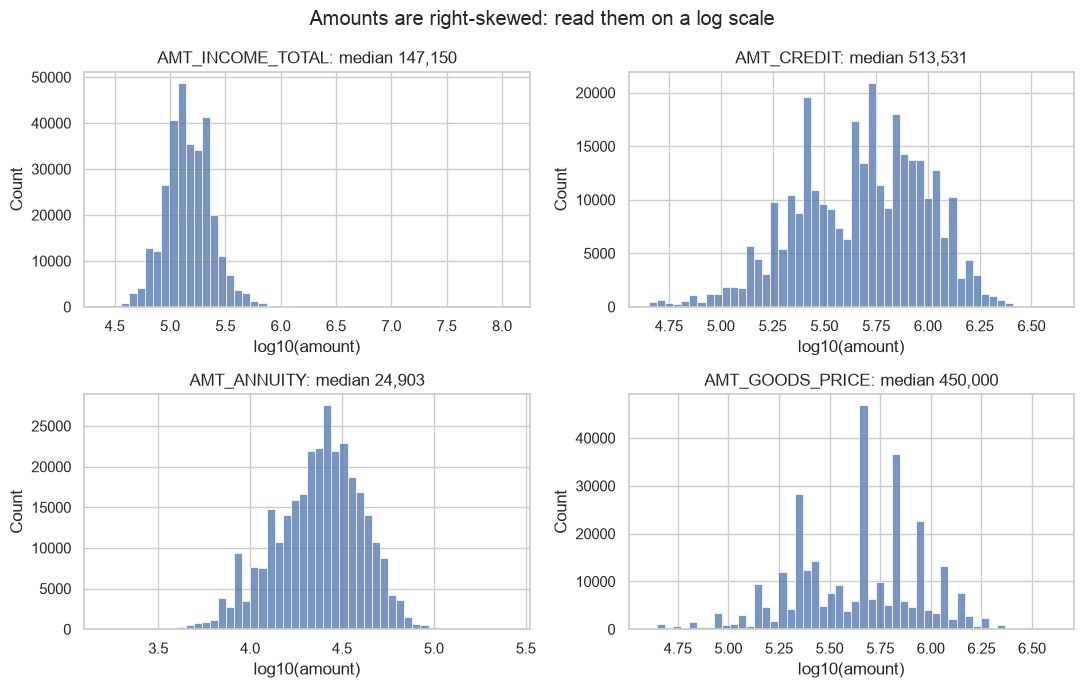

In [32]:
money = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), money):
    # Plot log10 of the amount (drop NaN first): money is right-skewed.
    sns.histplot(np.log10(app[col].dropna()), bins=50, ax=ax)
    ax.set_title(f"{col}: median {app[col].median():,.0f}")
    ax.set_xlabel("log10(amount)")
fig.suptitle("Amounts are right-skewed: read them on a log scale")
fig.tight_layout()

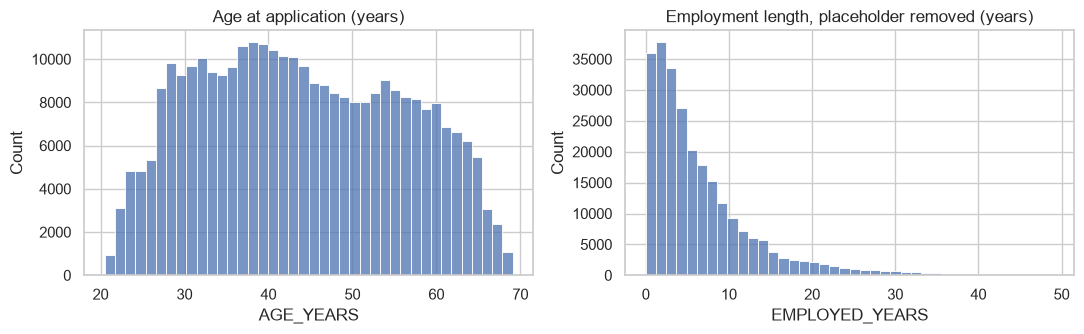

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(app["AGE_YEARS"], bins=40, ax=axes[0]).set_title("Age at application (years)")
sns.histplot(app["EMPLOYED_YEARS"], bins=40, ax=axes[1]).set_title("Employment length, placeholder removed (years)")
fig.tight_layout()

## 5. Default rate by variable

The core tool of credit EDA: cut a variable into groups and look at the **default rate per group, with the count**. A 40 % default rate on 5 clients is noise.

In [34]:
def default_rate_by(df: pd.DataFrame, col: str, q: int = 10) -> pd.DataFrame:
    """Count and default rate per decile (numeric column) or per category (text column)."""
    if pd.api.types.is_numeric_dtype(df[col]):
        # Cut `col` into q quantile bins with pd.qcut; drop duplicate edges.
        groups = pd.qcut(df[col], q, duplicates="drop")
    else:
        groups = df[col].fillna("Missing")
    # Aggregate TARGET per group: number of rows and mean.
    out = df.groupby(groups, observed=True)["TARGET"].agg(["size", "mean"])
    return out.rename(columns={"size": "count", "mean": "default_rate"})


def plot_default_rate(table: pd.DataFrame, title: str, ax: plt.Axes) -> None:
    """Bar chart of the default rate per group, count written on each bar."""
    ax.bar(range(len(table)), table["default_rate"])
    for i, (n, rate) in enumerate(zip(table["count"], table["default_rate"])):
        ax.text(i, rate, f"{n:,}", ha="center", va="bottom", fontsize=7)
    ax.axhline(target_rate, color="black", ls="--", lw=1)
    labels = [f"{g.left:.2f} to {g.right:.2f}" if isinstance(g, pd.Interval) else str(g) for g in table.index]
    ax.set_xticks(range(len(table)), labels, rotation=45, ha="right", fontsize=7)
    ax.set_ylabel("default rate")
    ax.set_title(title, fontsize=10)


default_rate_by(app, "EXT_SOURCE_3").round(4)

,count,default_rate
EXT_SOURCE_3,,
"(-0.000473, 0.228]",24701,0.2000
"(0.228, 0.33]",24744,0.1275
"(0.33, 0.408]",25057,0.0951
"(0.408, 0.476]",24689,0.0798
"(0.476, 0.535]",24186,0.0618
"(0.535, 0.592]",25392,0.0534
"(0.592, 0.643]",24725,0.0474
"(0.643, 0.694]",24745,0.0421
"(0.694, 0.749]",23675,0.0353


**Result:** 10 deciles of about 24,600 rows each (missing values are left out here), default rate from 20.0 % in the first decile to 3.2 % in the last.

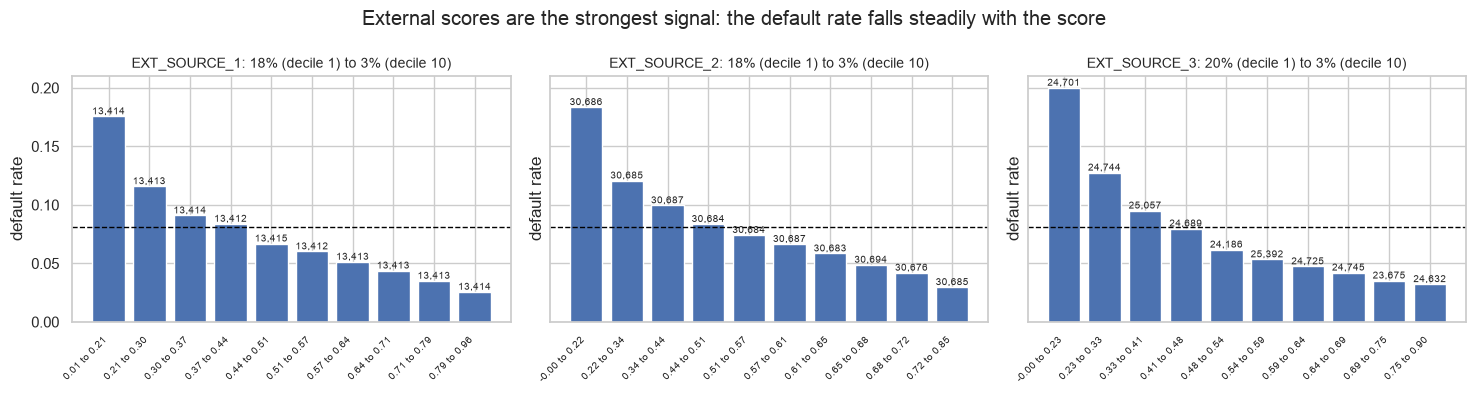

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    t = default_rate_by(app, col)
    plot_default_rate(t, f"{col}: {t['default_rate'].iloc[0]:.0%} (decile 1) to {t['default_rate'].iloc[-1]:.0%} (decile 10)", ax)
fig.suptitle("External scores are the strongest signal: the default rate falls steadily with the score")
fig.tight_layout()
fig.savefig(FIGURES / "eda_ext_sources.png", dpi=150, bbox_inches="tight")

**Finding:** the three external scores are monotonic: from about 18 to 20 % default in the lowest decile to about 3 % in the highest.
**Decision:** they are the backbone of the scorecard. Monotonic relationships are exactly what WoE binning with a monotonic constraint captures.

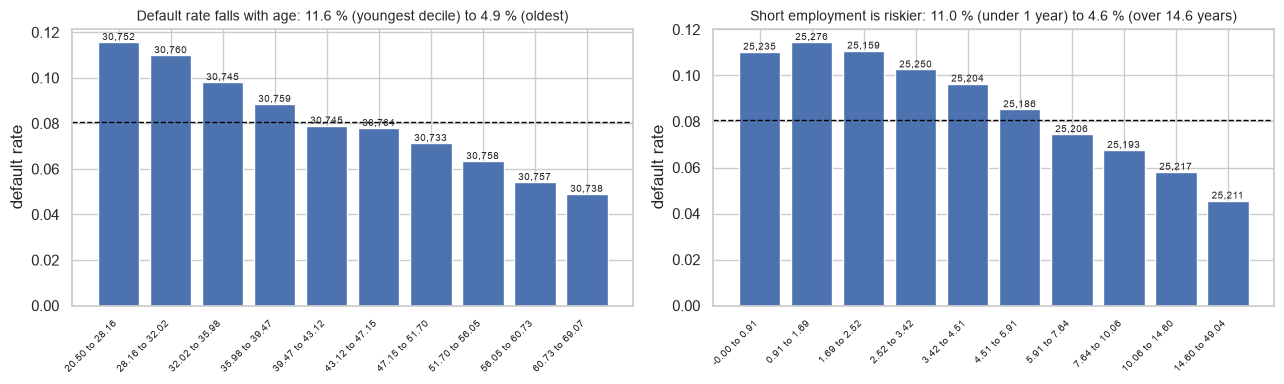

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_default_rate(default_rate_by(app, "AGE_YEARS"), "Default rate falls with age: 11.6 % (youngest decile) to 4.9 % (oldest)", axes[0])
plot_default_rate(default_rate_by(app, "EMPLOYED_YEARS"), "Short employment is riskier: 11.0 % (under 1 year) to 4.6 % (over 14.6 years)", axes[1])
fig.tight_layout()
fig.savefig(FIGURES / "eda_age_employment.png", dpi=150, bbox_inches="tight")

**Result:** age deciles go from 11.57 % default (20.5 to 28.2 years) down to 4.90 % (60.7 to 69.1 years). Employment deciles go from 11.03 % (under 0.9 year) down to 4.56 % (14.6 years and more), placeholder rows excluded.

**Finding:** age and employment length are monotonic risk drivers, once the placeholder is removed.
**Decision:** both are scorecard candidates, built from the cleaned `EMPLOYED_YEARS` (placeholder as NaN, its own bin).

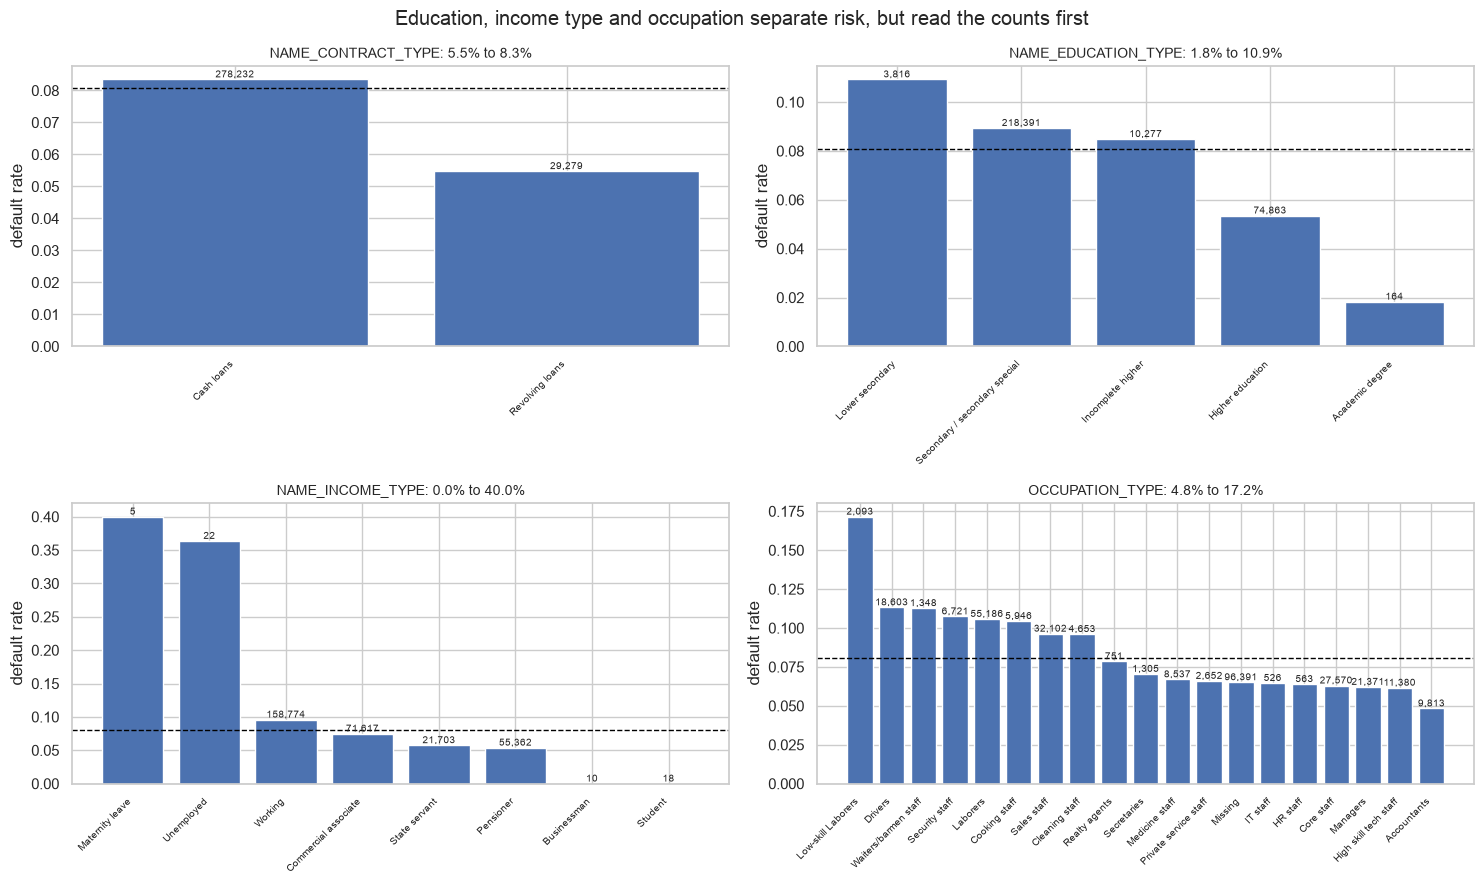

In [37]:
cats = ["NAME_CONTRACT_TYPE", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "OCCUPATION_TYPE"]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.ravel(), cats):
    # Sort the categories by default rate before plotting.
    t = default_rate_by(app, col).sort_values("default_rate", ascending=False)
    plot_default_rate(t, f"{col}: {t['default_rate'].min():.1%} to {t['default_rate'].max():.1%}", ax)
fig.suptitle("Education, income type and occupation separate risk, but read the counts first")
fig.tight_layout()
fig.savefig(FIGURES / "eda_categoricals.png", dpi=150, bbox_inches="tight")

**Result:** `Maternity leave` shows 40.0 % default on **5** clients, `Unemployed` 36.4 % on 22: noise. Low-skill laborers 17.2 % on 2,093 clients is a real signal; accountants 4.8 % on 9,813.

**Finding:** rare categories produce extreme default rates that will not generalise.
**Decision:** merge rare categories (minimum bin size, about 5 % of rows, in optbinning) and keep `OCCUPATION_TYPE` missing as its own category.

## 6. First look at predictive power: Information Value

For one variable cut into bins: share of goods $g_i$ and share of bads $b_i$ in bin $i$.

$$\text{WoE}_i = \ln\frac{g_i}{b_i} \qquad \text{IV} = \sum_i (g_i - b_i)\,\text{WoE}_i$$

Usual reading (Siddiqi): below 0.02 useless, 0.02 to 0.1 weak, 0.1 to 0.3 medium, above 0.3 strong, above 0.5 suspicious (check for leakage).

In [44]:
def quick_iv(df: pd.DataFrame, col: str, q: int = 10) -> float:
    """Information Value with decile bins; missing values get their own bin."""
    x = df[col]
    if pd.api.types.is_numeric_dtype(x):
        x = pd.qcut(x, q=q, duplicates="drop").astype(str)  # NaN becomes the bin "nan"
    x = x.fillna("Missing")
    counts = pd.crosstab(x, df["TARGET"]) + 0.5  # +0.5 avoids log(0) in a bin with no bad
    # Share of all goods (column 0) and of all bads (column 1) in each bin.
    dist_good = counts[0] / counts[0].sum()
    dist_bad = counts[1] / counts[1].sum()
    # WoE per bin, then IV.
    woe = np.log(dist_good / dist_bad)
    return float(((dist_good - dist_bad) * woe).sum())


candidates = [c for c in app.columns if c not in ("SK_ID_CURR", "TARGET", "DAYS_BIRTH")]
iv = pd.Series({c: quick_iv(app, c) for c in candidates}).sort_values(ascending=False)
iv.head(15).round(3)

EXT_SOURCE_3              0.329
EXT_SOURCE_2              0.306
EXT_SOURCE_1              0.151
EMPLOYED_YEARS            0.111
DAYS_EMPLOYED             0.101
AMT_GOODS_PRICE           0.092
AGE_YEARS                 0.084
OCCUPATION_TYPE           0.083
ORGANIZATION_TYPE         0.073
NAME_INCOME_TYPE          0.058
NAME_EDUCATION_TYPE       0.051
DAYS_LAST_PHONE_CHANGE    0.047
AMT_CREDIT                0.045
CODE_GENDER               0.039
FLOORSMAX_AVG             0.038
dtype: float64

**Result:** `EXT_SOURCE_3` 0.329, `EXT_SOURCE_2` 0.306, `EXT_SOURCE_1` 0.151, `EMPLOYED_YEARS` 0.111, `DAYS_EMPLOYED` 0.101. `CODE_GENDER` is in the top 15 with 0.039.

Three things to notice:
- `EXT_SOURCE_1` has a clean monotonic decile curve but a lower IV: 56 % of its rows sit in the missing bin, whose default rate is close to average, so it carries less information overall.
- `EMPLOYED_YEARS` (placeholder as NaN) beats `DAYS_EMPLOYED` (placeholder as a number): cleaning the placeholder already gains IV.
- Nothing is above 0.5, so no obvious target leakage in the application table.

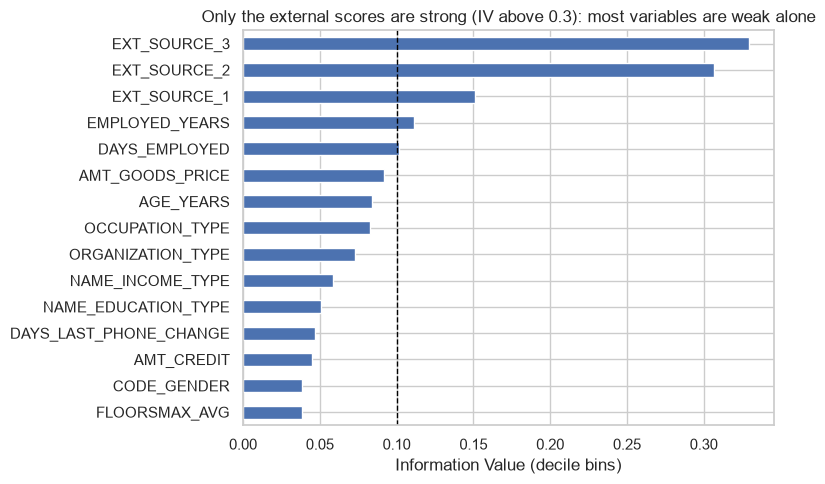

In [45]:
fig, ax = plt.subplots(figsize=(8, 5))
iv.head(15).sort_values().plot.barh(ax=ax)
ax.axvline(0.1, color="black", ls="--", lw=1)
ax.set_xlabel("Information Value (decile bins)")
ax.set_title("Only the external scores are strong (IV above 0.3): most variables are weak alone")
fig.tight_layout()
fig.savefig(FIGURES / "eda_iv_top15.png", dpi=150, bbox_inches="tight")

In [50]:
top_numeric = [c for c in iv.index[:25] if pd.api.types.is_numeric_dtype(app[c])][:15]
# Spearman correlation (rank based, robust to outliers) between the top variables.
corr = app[top_numeric].corr(method='spearman')
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
upper[upper.abs() > 0.8].sort_values(ascending=False).round(3)

FLOORSMAX_AVG    FLOORSMAX_MEDI    0.995
FLOORSMAX_MEDI   FLOORSMAX_MODE    0.986
AMT_GOODS_PRICE  AMT_CREDIT        0.985
FLOORSMAX_AVG    FLOORSMAX_MODE    0.982
EMPLOYED_YEARS   DAYS_EMPLOYED    -1.000
dtype: float64

**Result:** `FLOORSMAX_AVG` vs `_MEDI` 0.995 (and the other triplet pairs at 0.98), `AMT_GOODS_PRICE` vs `AMT_CREDIT` 0.985, `EMPLOYED_YEARS` vs `DAYS_EMPLOYED` -1.000 (the same variable, rescaled).

In [51]:
# The building triplets: _AVG, _MODE and _MEDI of the same feature.
app[["APARTMENTS_AVG", "APARTMENTS_MODE", "APARTMENTS_MEDI"]].corr(method="spearman").round(3)

,APARTMENTS_AVG,APARTMENTS_MODE,APARTMENTS_MEDI
APARTMENTS_AVG,1.000,0.965,0.995
APARTMENTS_MODE,0.965,1.000,0.970
APARTMENTS_MEDI,0.995,0.970,1.000


**Result:** `_AVG` vs `_MEDI` 0.995, `_AVG` vs `_MODE` 0.965.

**Finding:** several top variables are near duplicates, and each building feature exists three times.
**Decision:** keep one version per building feature (`_AVG`), and drop one variable of each pair above 0.8 inside the scorecard (multicollinearity makes logistic coefficients unstable and their signs unreliable). XGBoost is less sensitive, but the duplicates still split SHAP importance.

## 7. Sensitive variables

A credit model scores natural persons: under the EU AI Act this is a **high-risk** use case (Annex III). Before using a variable, ask: is it allowed, is it justified by risk, and can I explain it to a rejected client?

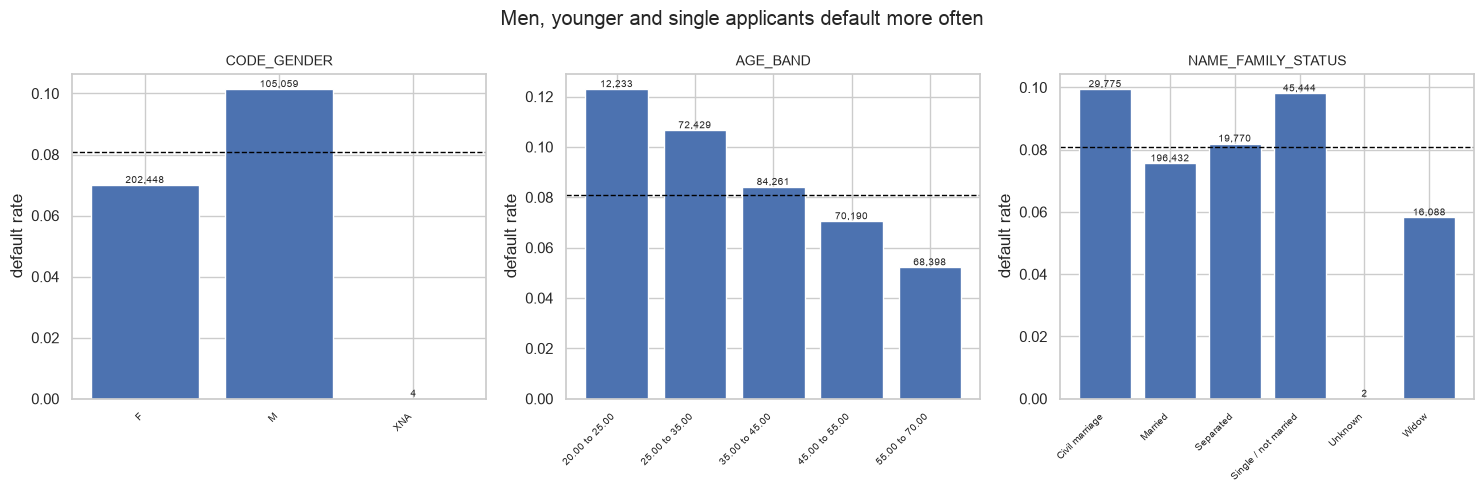

In [54]:
# Age bands with pd.cut: 20-25, 25-35, 35-45, 45-55, 55-70.
app["AGE_BAND"] = pd.cut(app["AGE_YEARS"], bins=[20, 25, 35, 45, 55, 70])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ["CODE_GENDER", "AGE_BAND", "NAME_FAMILY_STATUS"]):
    t = default_rate_by(app, col) if col != "AGE_BAND" else app.groupby("AGE_BAND", observed=True)["TARGET"].agg(count="size", default_rate="mean")
    plot_default_rate(t, col, ax)
fig.suptitle("Men, younger and single applicants default more often")
fig.tight_layout()
fig.savefig(FIGURES / "eda_sensitive.png", dpi=150, bbox_inches="tight")

**Result:** men 10.14 % vs women 7.00 % (4 rows `XNA`); age band 20 to 25: 12.29 %, down to 5.22 % for 55 to 70; civil marriage 9.94 % and single 9.81 % vs widow 5.82 %.

**Decision:**

1. **CODE_GENDER is excluded from the model.** In the EU, refusing credit because of sex is illegal (Directive 2004/113/EC on access to goods and services, transposed in the Belgian Gender Act of 2007), even if men default more often here (10.14 % vs 7.00 %). It also fails the explainability test: no bank can tell a client "you are refused because you are a man".
2. **CODE_GENDER stays in the data, for the audit only.** Removing it does not remove its proxies: occupation, income type or family status can rebuild it (e.g. drivers, mostly men, default at 11.3 %). So at the chosen threshold, I measure approval rate and default rate per gender (fairness check), as the AI Act asks high-risk systems to examine bias in their data (Article 10).
3. **Age stays a candidate feature.** Age is also a protected characteristic, but in credit it has an objective business justification (job seniority, income stability, loan term before retirement), and the reason can be explained as "short credit and employment history", not "too young". Default falls from 12.29 % (20 to 25) to 5.22 % (55 to 70); the fairness check reports results per age band.

## 8. Key findings

1. - **Finding:** 8.07 % of applications are bads; approving everyone gives 91.93 % accuracy and catches zero defaulter. 
   - **Decision:** never report accuracy; use Gini, KS, PR-AUC and Brier, and stratify every split on TARGET.
2. - **Finding:** 18.0 % of clients have DAYS_EMPLOYED = 365243 (55,352 pensioners, 22 unemployed) and default less (5.40 % vs 8.66 %). 
   - **Decision:** replace by NaN and add a flag DAYS_EMPLOYED_ANOM.
3. - **Finding:** missingness predicts default: no building data means 9.15 % default vs 6.96 %, no EXT_SOURCE_3 means 9.31 % vs 7.77 %. 
   - **Decision:** do not drop columns because they are empty and do not impute blindly; missing values get their own bin in the scorecard.
4. - **Finding:** the three external scores are the strongest signal (IV 0.329, 0.306, 0.151) and monotonic, from 20.0 % default in the lowest EXT_SOURCE_3 decile to 3.2 % in the highest.     
   - **Decision:** they are the backbone of the scorecard, binned with a monotonic trend.
5. - **Finding:** strong redundancy: AMT_GOODS_PRICE vs AMT_CREDIT at 0.985, and each building feature exists three times (_AVG vs _MEDI at 0.995). 
   - **Decision:** keep only _AVG for building features, replace the redundant amounts by a ratio CREDIT_GOODS_RATIO, and drop one variable of each pair above 0.8 in the scorecard.